## C1 - WEEK 4

- Adrià Cantarero Carreras  (1809773@uab.cat)
- Ivan Martin Campoy (1673246@uab.cat)
- Irene Pumares Benaiges (1810704@uab.cat)
- Lavish Ramchandani (1691238@uab.cat)

In [ ]:
import sys
sys.path.append("..")  # repo root
#needed libraries

import os
import re
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## Common pipeline

Every photo goes through the same steps before the local descriptors:

1. Denoising (Week 3, Task 1): impulse / additive noise detector, median 3x3 only on the photos detected as noisy.
2. Painting detection (Week 3, Task 3): wall colour model in Lab (Week 2 method C) + hole filling + connected components, with two small changes for the test set, explained in that section.
3. Crop the bounding box of every painting from the denoised photo.
4. Local descriptors + matching (Tasks 1-2, next sections) give a score per BBDD image for every crop.
5. Output: for every photo, one list per painting with the top-10 BBDD ids, or `[-1]` if the painting is unknown.

Only the selected configuration of every Week 3 step is copied here.

### Data

In [105]:
#paths and results folder
bbdd_path = "./data/BBDD"
qsd1_path = "./data/qsd1_w4"
results_dir = "./results"
os.makedirs(results_dir, exist_ok=True)

def read_image(img_path):
    image = cv2.imread(img_path)
    if image is None:
        raise IOError(f"Could not read {img_path}")
    return image

#sort files in natural order
def return_number(string):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', string)]

def load_query_set(folder):
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(".jpg")], key=return_number)
    return files, [read_image(os.path.join(folder, f)) for f in files]

def load_pickle(path):
    #None if the file is not in the dataset
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)

def as_id_list(g):
    #one ground truth entry -> list of int bbdd ids (one per painting, -1 = not in the museum)
    return [int(x) for x in g] if isinstance(g, (list, tuple, np.ndarray)) else [int(g)]

#type of every photo (only used to analyse the results, never to retrieve)
def aug_type(a):
    a = str(a).lower()
    if "noise" in a:
        return "noise"
    if "color" in a or "hue" in a:
        return "color"
    return "none"

#museum
bbdd_files, bbdd_imgs = load_query_set(bbdd_path)
bbdd_ids = np.array([int(re.findall(r"\d+", f)[-1]) for f in bbdd_files]) #bbdd_00012.jpg -> 12
bbdd_index = {b: i for i, b in enumerate(bbdd_ids)} #bbdd id -> position in bbdd_imgs

#QSD1-W4 photos and ground truth (correct answers): one bbdd id per painting, left to right (-1 = painting not in the museum)
qsd1_files, qsd1_imgs = load_query_set(qsd1_path)
qsd1_gt = [as_id_list(g) for g in load_pickle(os.path.join(qsd1_path, "gt_corresps.pkl"))]
qsd1_n_paintings = np.array([len(g) for g in qsd1_gt])

#optional files (only to analyse the results)
qsd1_augs = load_pickle(os.path.join(qsd1_path, "augmentations.pkl"))
qsd1_type = np.array([aug_type(a) for a in qsd1_augs]) if qsd1_augs is not None else None
mask_paths = [os.path.join(qsd1_path, os.path.splitext(f)[0] + ".png") for f in qsd1_files]
qsd1_gt_masks = [cv2.imread(p, cv2.IMREAD_GRAYSCALE) > 0 for p in mask_paths] if all(map(os.path.exists, mask_paths)) else None

n_unknown = sum(g.count(-1) for g in qsd1_gt)
print(f"BBDD: {len(bbdd_imgs)} images")
print(f"QSD1-W4: {len(qsd1_imgs)} photos, {qsd1_n_paintings.sum()} paintings "
      f"({np.sum(qsd1_n_paintings == 2)} photos with two), {n_unknown} paintings not in the museum")
if qsd1_type is not None:
    print("photo types:", pd.Series(qsd1_type).value_counts().to_dict())
print("Ground truth masks available:", qsd1_gt_masks is not None)

BBDD: 287 images
QSD1-W4: 30 photos, 39 paintings (9 photos with two), 10 paintings not in the museum
photo types: {'color': 12, 'none': 9, 'noise': 9}
Ground truth masks available: True


### Denoising (Week 3, Task 1)

Copied without changes: the thresholds were chosen on QSD1-W3 and the filter is the best one of the Week 3 comparison (median 3x3, best PSNR and SSIM). The median filter is only applied to the photos detected as noisy.

In [106]:
# Additive noise (a small random value added to each pixel)

LAPLACIAN_DIFF = np.array([[1, -2, 1],
                           [-2, 4, -2],
                           [1, -2, 1]], dtype=np.float64)

def additive_noise(img):
    sigmas = []
    for c in range(img.shape[2]):
        residual = cv2.filter2D(img[..., c].astype(np.float64), -1, LAPLACIAN_DIFF)[1:-1, 1:-1]   #drop the border (padding)
        sigmas.append(np.median(np.abs(residual)) / (0.6745 * 6))
    return np.mean(sigmas)

# Impulse noise (a pixel is replaced by a random value)

T_ISOLATED = 30 #grey levels a pixel must stand out from all its neighbours (~10% of the 0-255 range)
RING = np.ones((3, 3), np.uint8)
RING[1, 1] = 0 #structuring element = the 8 neighbours, without the centre pixel

def impulsive_noise(img, t=T_ISOLATED):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.int16)
    neigh_max = cv2.dilate(gray, RING) #max of the 8 neighbours
    neigh_min = cv2.erode(gray, RING) #min of the 8 neighbours
    return np.mean((gray > neigh_max + t) | (gray < neigh_min - t))

ISOLATED_THRESHOLD = 0.01 #fraction of isolated pixels
SIGMA_THRESHOLD = 8.0 #estimated noise std

def is_noisy(img):
    if impulsive_noise(img) > ISOLATED_THRESHOLD:
        return True
    if additive_noise(img) > SIGMA_THRESHOLD:
        return True
    return False

def denoise(img):
    #median 3x3 (best filter of Week 3) only if the photo is detected as noisy
    return cv2.medianBlur(img, 3) if is_noisy(img) else img

In [107]:
qsd1_detected = np.array([is_noisy(img) for img in qsd1_imgs])
qsd1_denoised = [denoise(img) for img in qsd1_imgs]
print("Detected as noisy:", [qsd1_files[i] for i in np.where(qsd1_detected)[0]])

#check with the real labels (only here, never used to decide)
if qsd1_type is not None:
    really_noisy = qsd1_type == "noise"
    print(f"Correctly detected: {np.sum(qsd1_detected & really_noisy)}/{really_noisy.sum()}")
    print(f"False positives: {np.sum(qsd1_detected & ~really_noisy)}/{np.sum(~really_noisy)}")

Detected as noisy: ['00003.jpg', '00008.jpg', '00012.jpg', '00017.jpg', '00019.jpg', '00022.jpg', '00023.jpg', '00024.jpg', '00025.jpg']
Correctly detected: 9/9
False positives: 0/21


### Painting detection (Week 3, Task 3)

Same method as Week 3: we learn the wall colour from the outer 3% of the photo, every pixel with a colour different enough from the wall is painting, then we fill the holes and keep the big connected components (at least 5% of the photo).

Two small changes, marked with `NEW` in the code. On QSD1-W4 they give the same result as Week 3, they are there so the method also works on the test set (QST1-W4):

1. Any number of paintings (`MAX_PAINTINGS = None`). Week 3 kept at most 2. QSD1-W4 has at most 2 paintings per photo, but the test set says "more than one picture per image", so it may have 3.
2. Order of the paintings (`ORDER = "auto"`). In Week 3 the paintings were always side by side, so we sorted them by their left edge. When one painting is above the other, both start at almost the same left edge and the order is random, so we sort them from top to bottom.

In [108]:
from functools import cmp_to_key

BORDER_RATIO = 0.03 #outer 3% of each side is assumed to be wall
W2_PARAMS = dict(tau=10, tau2=1.5, rho=0.6) #best Week 2 configuration (Lab, method C)
MIN_AREA = 0.05 #a painting covers at least 5% of the photo
MAX_PAINTINGS = None #NEW: None = any number of paintings (Week 3: 2)
ORDER = "auto" #NEW: "left-right" (Week 3) or "auto" (top to bottom when one painting is above the other)

def border_region(shape, border_ratio=BORDER_RATIO):
    #boolean map of the outer strip of the photo
    h, w = shape[:2]
    bh, bw = max(1, round(border_ratio * h)), max(1, round(border_ratio * w))
    region = np.zeros((h, w), dtype=bool)
    region[:bh, :] = True
    region[-bh:, :] = True
    region[:, :bw] = True
    region[:, -bw:] = True
    return region

def wall_colour_mask(image, tau=10, tau2=1.5, rho=0.6):
    #Week 2 method C in Lab: True = painting
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB).astype(np.float32)
    chroma, luma = lab[..., 1:], lab[..., 0]
    border = border_region(luma.shape)
    dist = np.sqrt(np.sum((chroma - np.median(chroma[border], axis=0)) ** 2, axis=-1)) #colour distance to the wall
    ratio = luma / (np.median(luma[border]) + 1e-6) #light relative to the wall
    return (dist > tau) | ((ratio < rho) & (dist > tau2))

def fill_holes(mask):
    #flood the background from the border; whatever background is not reached is a hole
    padded = np.pad(mask.astype(np.uint8), 1, constant_values=0)
    ff_mask = np.zeros((padded.shape[0] + 2, padded.shape[1] + 2), np.uint8)
    cv2.floodFill(padded, ff_mask, (0, 0), 1)
    return mask.astype(bool) | (padded[1:-1, 1:-1] == 0)

def reading_order(a, b, order=ORDER):
    #NEW: which of two paintings goes first in the result
    #why: with one painting above the other, the left edge gives a random order (both start almost at the same x)
    #"auto": if the two paintings share most of their horizontal range (one is above the other), the top one goes first
    #otherwise, the left one goes first (as in Week 3)
    if order == "auto":
        x_overlap = min(a[2], b[2]) - max(a[0], b[0])
        if x_overlap > 0.5 * min(a[2] - a[0], b[2] - b[0]):
            return a[1] - b[1]
    return a[0] - b[0]

def painting_regions(mask, min_area=MIN_AREA, max_paintings=MAX_PAINTINGS, order=ORDER):
    #the largest components (at most max_paintings, None = no limit) with at least min_area of the photo, in order (see reading_order)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    keep = [1 + k for k in np.argsort(-areas) if areas[k] >= min_area * mask.size]
    if max_paintings is not None:
        keep = keep[:max_paintings]
    box = lambda label: (stats[label, 0], stats[label, 1], stats[label, 0] + stats[label, 2], stats[label, 1] + stats[label, 3])
    keep.sort(key=cmp_to_key(lambda l1, l2: reading_order(box(l1), box(l2), order)))
    return [labels == label for label in keep]

def segment_paintings(image, min_area=MIN_AREA, max_paintings=MAX_PAINTINGS, order=ORDER):
    #-> list of boolean masks, one per painting, in order (see reading_order)
    regions = painting_regions(fill_holes(wall_colour_mask(image, **W2_PARAMS)), min_area, max_paintings, order)
    return regions if regions else [np.ones(image.shape[:2], dtype=bool)] #nothing found: the whole photo

def union(regions):
    #one mask with all the paintings of the photo
    return np.any(regions, axis=0)

def bbox_crop(image, region):
    ys, xs = np.nonzero(region)
    return image[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def draw_regions(image, regions, gt=None):
    #detected paintings: light colour + outline + order number; correct mask outline in green
    colours = [(255, 120, 0), (0, 120, 255), (170, 0, 255), (255, 0, 120)]
    out = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).copy()
    thick = max(2, image.shape[1] // 250)
    for k, r in enumerate(regions):
        c = colours[k % len(colours)]
        out[r] = (0.75 * out[r] + 0.25 * np.array(c)).astype(np.uint8)
        cnts, _ = cv2.findContours(r.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, c, thick)
        ys, xs = np.nonzero(r)
        cv2.putText(out, str(k + 1), (int(xs.mean()), int(ys.mean())), cv2.FONT_HERSHEY_SIMPLEX,
                    image.shape[1] / 300, c, 3 * thick)
    if gt is not None:
        cnts, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, (0, 255, 0), thick)
    return out

In [109]:
EPS = 1e-10

def mask_prf(pred, gt):
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)
    p, r = tp / (tp + fp + EPS), tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def evaluate_segmentation(regions):
    #right number of paintings per photo and, if the correct masks are available, pixel precision / recall / F1
    count_ok = np.array([len(r) == n for r, n in zip(regions, qsd1_n_paintings)])
    out = {"Right count": count_ok.sum()}
    if qsd1_gt_masks is not None:
        p, r, f1 = np.mean([mask_prf(union(rr), g) for rr, g in zip(regions, qsd1_gt_masks)], axis=0)
        out.update({"Precision": p, "Recall": r, "F1": f1})
    return out

qsd1_regions = [segment_paintings(img) for img in qsd1_denoised]
df_seg = pd.DataFrame([evaluate_segmentation(qsd1_regions)])
df_seg.to_csv(os.path.join(results_dir, "pipeline_segmentation.csv"), index=False)
display(df_seg.round(4))
wrong_count = [(qsd1_files[i], len(r), int(n)) for i, (r, n) in enumerate(zip(qsd1_regions, qsd1_n_paintings)) if len(r) != n]
print("photos with a wrong number of paintings (file, found, correct):", wrong_count)

per_photo = pd.DataFrame([{"file": f, **dict(zip(["Precision", "Recall", "F1"], mask_prf(union(r), g)))}
                          for f, r, g in zip(qsd1_files, qsd1_regions, qsd1_gt_masks)])
display(per_photo.sort_values("F1").head(6).round(3))

,Right count,Precision,Recall,F1
0,26,0.9463,0.8884,0.8976


photos with a wrong number of paintings (file, found, correct): [('00016.jpg', 1, 2), ('00020.jpg', 1, 2), ('00026.jpg', 2, 1), ('00028.jpg', 1, 2)]


,file,Precision,Recall,F1
17,00017.jpg,0.885,0.102,0.183
26,00026.jpg,0.998,0.392,0.563
28,00028.jpg,0.968,0.539,0.692
11,00011.jpg,0.995,0.741,0.849
2,00002.jpg,0.898,0.814,0.854
16,00016.jpg,0.951,0.790,0.863


- 26 of the 30 photos have the right number of paintings. The masks are worse than in QSD2-W3 (F1 0.898 against 0.967) because of the low recall (0.888). It comes from two problems (see the photos with the lowest F1 above):
  - Paintings not found: the white drawings on the white wall (right painting of 00016, top painting of 00028). Their colour is almost the same as the wall, so the colour rule only keeps small pieces of the frame and the drawing, too small to count as a painting. Same problem as 00002 in Week 3.
  - Paintings only partly found: 00017 (only 10% of the painting, its white stripes have the colour of the wall), 00026 (39%, the grey tiles have the colour of the wall, and the part found is cut in two pieces), 00011 (74%) and the left painting of 00002. In 00017 the number of paintings is right, so it does not appear in the list of wrong counts.
- 00020: the two paintings are found as one region, so they end up in the same crop.
- Cost for the retrieval: 5 of the 39 paintings will be wrong whatever descriptor we use (280 in 00016, 47 and 13 in 00028, and 272 and 117 in 00020), so the best possible map@1 is about 34/39 = 0.872.
- 00017, 00026 and 00011, the photos with the worst partial masks, are paintings that are not in the museum, so on QSD1-W4 they do not cost anything in the retrieval. But they make the unknown detection easier than it should be: a small crop has few details, so it gets few matches and looks "unknown" partly because the crop is small. A painting of the museum found as badly in the test set would look unknown too.
- With the local descriptors (next sections), a mask that cuts part of the painting or keeps some wall should not be a big problem: they look for small details of the painting, and a cut painting still has many of them. We will check it in Task 3. But a painting that is not found, or two paintings in the same crop, cannot be fixed by the descriptors.

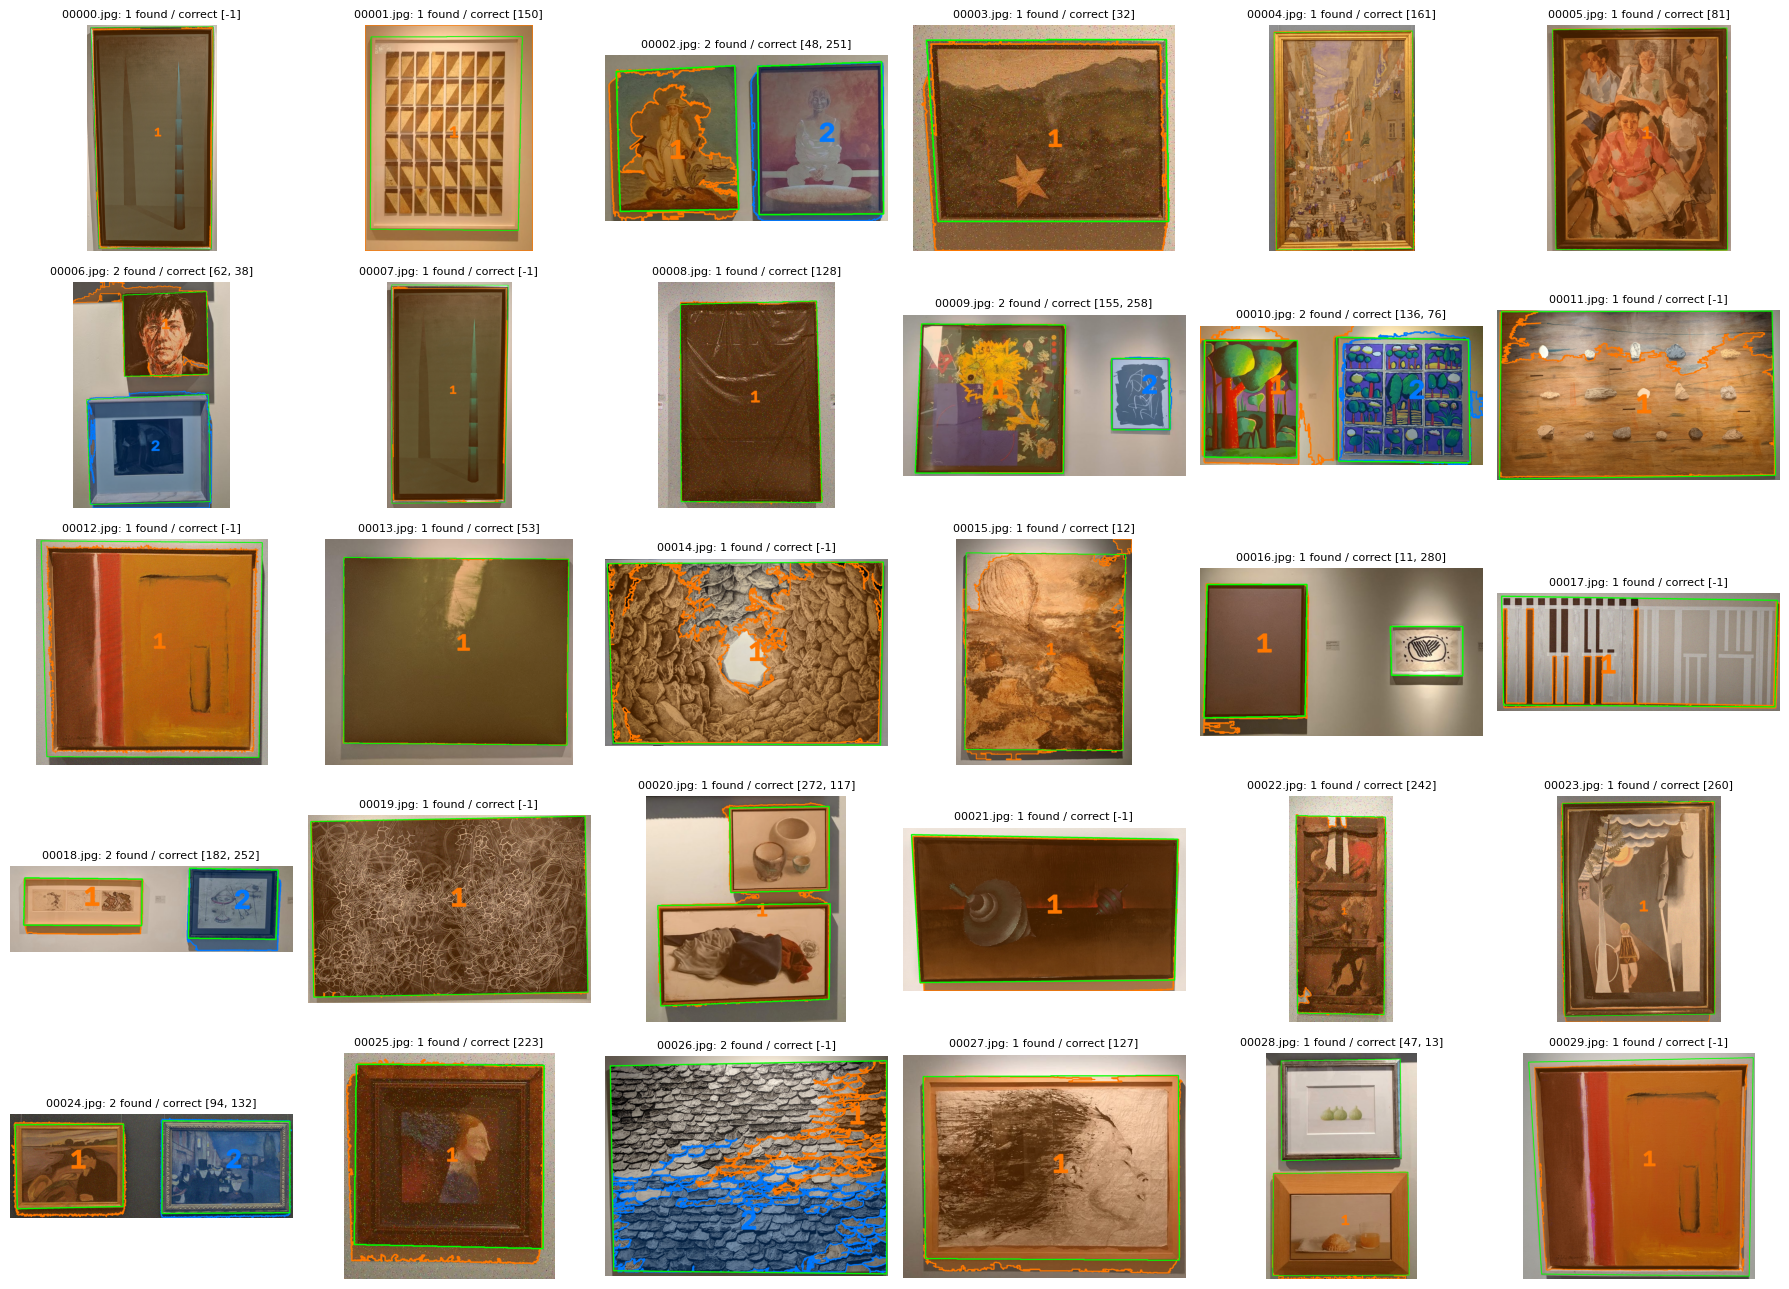

In [110]:
#visual check: every QSD1-W4 photo with its detected paintings (number = our order, correct mask outline in green)
n_cols = 6
n_rows = int(np.ceil(len(qsd1_files) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 2.6 * n_rows), squeeze=False)
for i, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if i < len(qsd1_files):
        gt = qsd1_gt_masks[i] if qsd1_gt_masks is not None else None
        ax.imshow(draw_regions(qsd1_imgs[i], qsd1_regions[i], gt))
        ax.set_title(f"{qsd1_files[i]}: {len(qsd1_regions[i])} found / correct {qsd1_gt[i]}", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "pipeline_qsd1_regions.png"), dpi=90, bbox_inches="tight")
plt.show()

#### Check: in which order are the paintings in `gt_corresps.pkl`?

`gt_corresps.pkl` gives, for every photo, the correct BBDD id of every painting, in a fixed order. The evaluation compares our first painting with the first correct one, and our second with the second, so if we find both paintings but in the other order, both count as wrong.

For every photo with two paintings: the photo with our detection (numbers 1 and 2 = our order) and the two correct BBDD images, in the order of `gt_corresps.pkl`. If "correct #1" is always the left painting, or the top one when one is above the other, our `ORDER = "auto"` is right. If not, use `ORDER = "left-right"`.

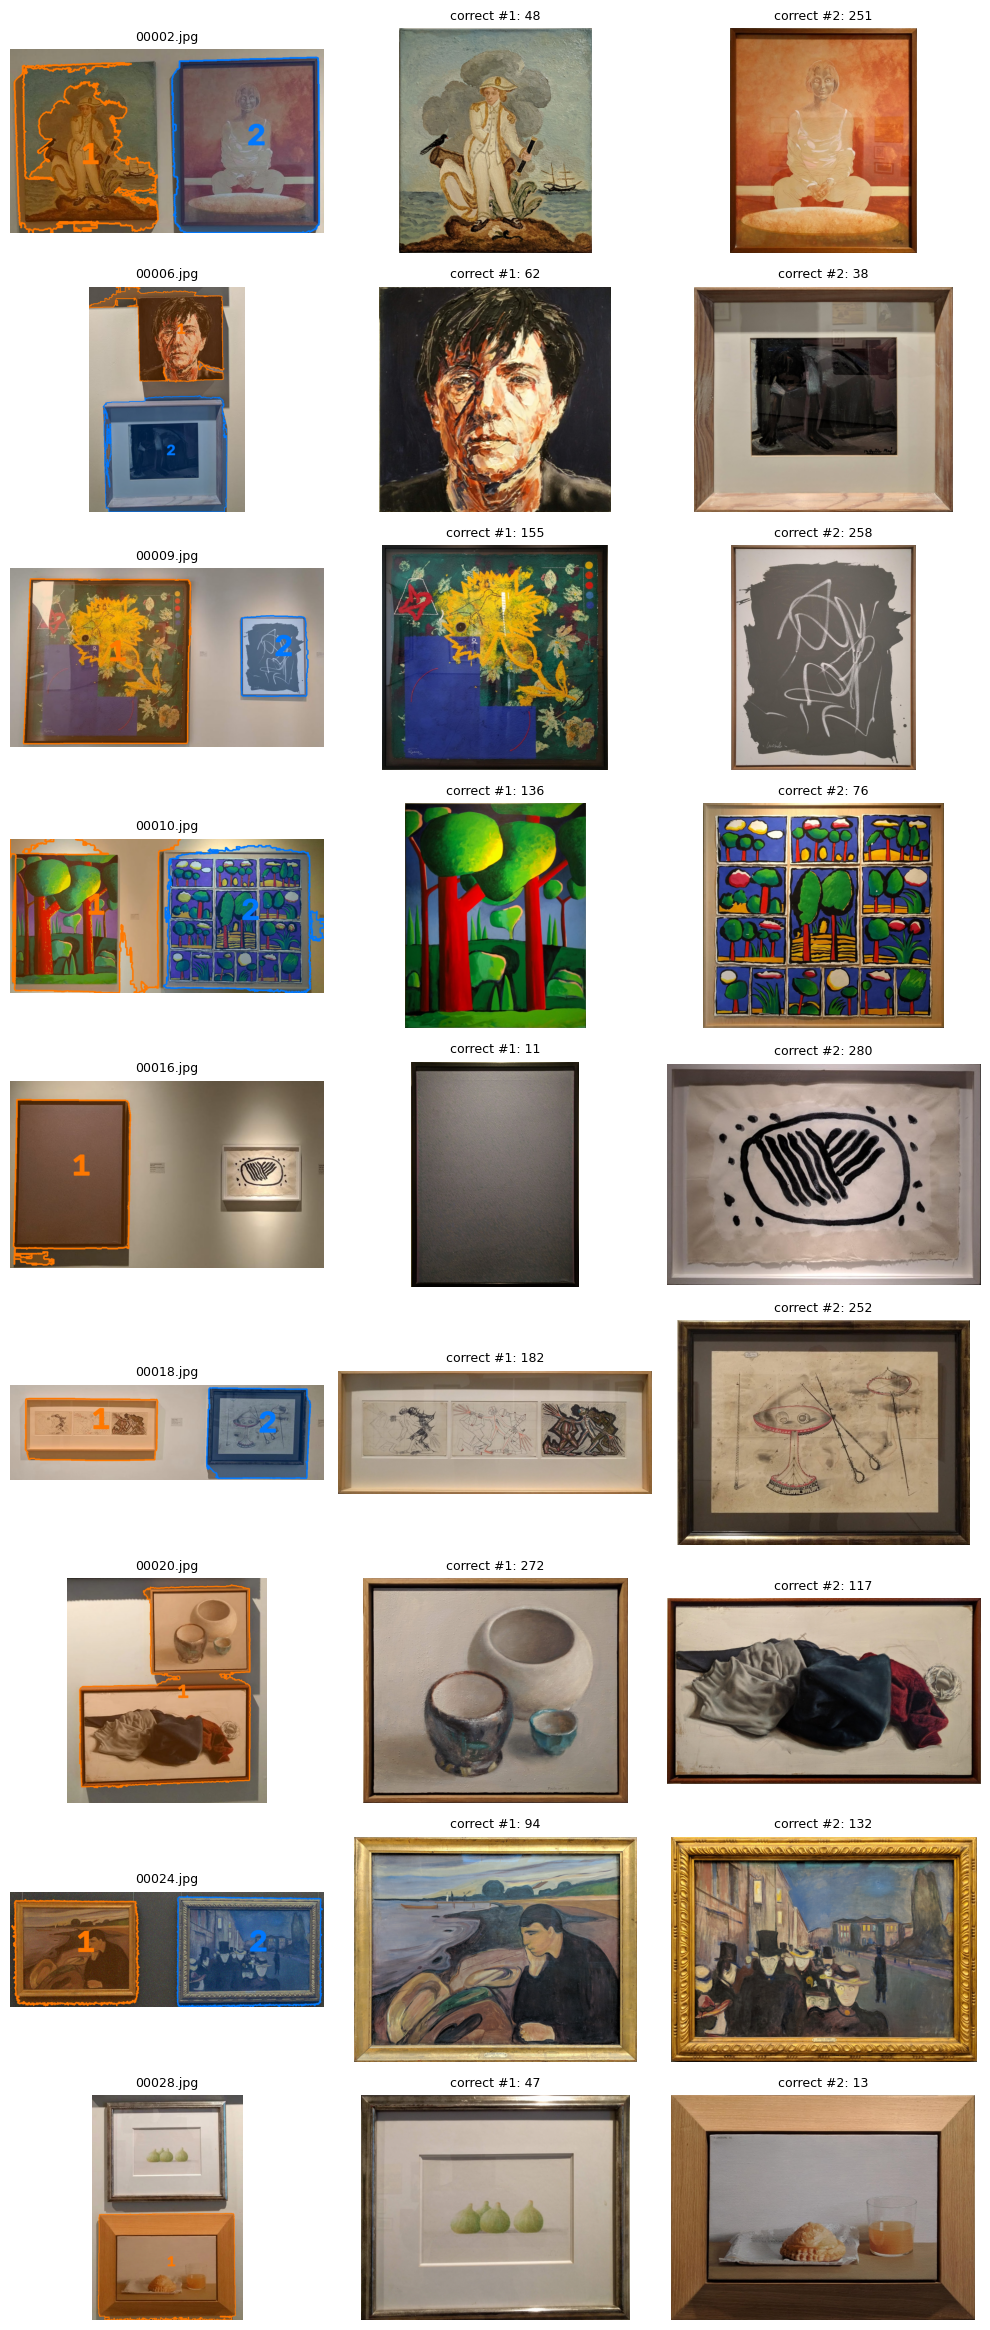

In [111]:
two = [i for i, g in enumerate(qsd1_gt) if len(g) >= 2]
fig, axes = plt.subplots(len(two), 3, figsize=(10, 2.6 * len(two)), squeeze=False)
for row, i in enumerate(two):
    axes[row, 0].imshow(draw_regions(qsd1_imgs[i], qsd1_regions[i]))
    axes[row, 0].set_title(qsd1_files[i], fontsize=9)
    for col, b in enumerate(qsd1_gt[i][:2]):
        ax = axes[row, col + 1]
        if b == -1:
            ax.text(0.5, 0.5, "not in the museum", ha="center", va="center", transform=ax.transAxes)
        else:
            ax.imshow(cv2.cvtColor(bbdd_imgs[bbdd_index[b]], cv2.COLOR_BGR2RGB))
        ax.set_title(f"correct #{col + 1}: {b}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "pipeline_gt_order.png"), dpi=90, bbox_inches="tight")
plt.show()

- When the paintings are side by side, "correct #1" is always the left one, as in Week 3.
- When one painting is above the other (00006, 00020, 00028), "correct #1" is always the top one, so `ORDER = "auto"` follows the same order as `gt_corresps.pkl`.
- On QSD1-W4 the Week 3 order (left edge) gives the same result, but in 00006 only by chance: the two paintings start at almost the same left edge, and some wall pixels stuck to the top painting make it start a bit more to the left. On the test set a pair like this could come out in the wrong order.
- In 00020 and 00028 only one painting is found, so the order cannot help: the one we find is compared with "correct #1".

### Painting crops

Input of the local descriptors: `qsd1_crops[i]` is the list of painting crops (BGR, left to right) of photo `i`, cut from the denoised photo. The museum images are used as they are (`bbdd_imgs`). `preprocess()` runs the whole common pipeline on a new photo (used for QST1-W4).

In [112]:
def preprocess(img):
    #common pipeline for one photo -> (denoised photo, painting masks left to right, painting crops)
    den = denoise(img)
    regions = segment_paintings(den)
    return den, regions, [bbox_crop(den, r) for r in regions]

qsd1_crops = [[bbox_crop(img, r) for r in regions] for img, regions in zip(qsd1_denoised, qsd1_regions)]
print("paintings per photo:", pd.Series([len(c) for c in qsd1_crops]).value_counts().sort_index().to_dict())
sizes = np.array([c.shape[:2] for cc in qsd1_crops for c in cc])
print(f"crop height {sizes[:, 0].min()}-{sizes[:, 0].max()} px, width {sizes[:, 1].min()}-{sizes[:, 1].max()} px")

paintings per photo: {1: 23, 2: 7}
crop height 198-3613 px, width 235-3547 px


### Output format and evaluation

Every local-descriptor method only has to provide a `score_fn(crop)` that returns one score per BBDD image (same order as `bbdd_ids`, higher = more similar, e.g. the number of good matches). `predict_paintings()` turns the scores into the output format:

- top-10 BBDD ids (integers) of every painting, sorted by score;
- `[-1]` if the best score is below `min_score` (painting not in the museum); `min_score=None` never returns `[-1]`.

Evaluation:

- map@k: one AP per painting, comparing the i-th correct painting with the i-th detected one (a painting that is not detected counts as 0). An unknown painting counts as correct only if its prediction is `[-1]`.
- F1 of the unknown detection: positive class = painting not in the museum (correct answer `-1`), to choose the threshold on the number of matches.

In [113]:
UNKNOWN = -1
K = 10

def apk(actual, predicted, k=10):
    #average precision at k for one query (actual = list of correct bbdd ids)
    predicted = list(predicted)[:k]
    score, hits = 0.0, 0
    for i, p in enumerate(predicted):
        if p in actual and p not in predicted[:i]:
            hits += 1
            score += hits / (i + 1)
    return score / min(len(actual), k) if actual else 0.0

def mapk(actual, predicted, k=10):
    return np.mean([apk(a, p, k) for a, p in zip(actual, predicted)])

def painting_mapk(actual, predicted, k=10):
    #actual / predicted: for every photo, one entry per painting
    aps = []
    for a_img, p_img in zip(actual, predicted):
        for j, a in enumerate(a_img):
            aps.append(apk([a], p_img[j], k) if j < len(p_img) else 0.0)
    return np.mean(aps)

def unknown_f1(actual, predicted):
    #precision / recall / F1 of the unknown detection, painting by painting (positive = not in the museum)
    tp = fp = fn = 0
    for a_img, p_img in zip(actual, predicted):
        for j in range(max(len(a_img), len(p_img))):
            is_unk = j < len(a_img) and a_img[j] == UNKNOWN
            said_unk = j < len(p_img) and list(p_img[j]) == [UNKNOWN]
            tp += is_unk and said_unk
            fp += said_unk and not is_unk
            fn += is_unk and not said_unk
    p, r = tp / (tp + fp + EPS), tp / (tp + fn + EPS)
    return p, r, 2 * p * r / (p + r + EPS)

def rank_to_output(scores, min_score=None, k=K):
    #scores: one value per BBDD image (higher = more similar) -> k integer bbdd ids, or [-1] if unknown
    scores = np.asarray(scores, dtype=np.float64)
    if min_score is not None and scores.max() < min_score:
        return [UNKNOWN]
    return [int(b) for b in bbdd_ids[np.argsort(-scores, kind="stable")[:k]]]

def predict_paintings(crops, score_fn, min_score=None, k=K):
    #crops: for every photo, its painting crops -> for every photo, one output list per painting
    return [[rank_to_output(score_fn(c), min_score, k) for c in cc] for cc in crops]

def check_submission(preds, n_photos, k=K):
    assert len(preds) == n_photos, "one entry per photo"
    for photo in preds:
        assert len(photo) >= 1, "at least one painting per photo"
        for painting in photo:
            assert painting == [UNKNOWN] or (len(painting) == min(k, len(bbdd_ids)) and all(type(i) is int for i in painting)), \
                "k integer ids per painting, or [-1]"

## TASK 1 & 2: Keypoints, local descriptors and matching

All the methods use the same input (`qsd1_crops`, `bbdd_imgs`) and the same output (`score_fn` → `predict_paintings`), so they can be compared directly.

### SIFT

#### Keypoints and descriptors

- Detector: Difference of Gaussians (DoG)
- Descriptor: 16x16 window around the keypoint, at its scale and rotated to its orientation, split in 4x4 cells, 8-bin histogram of gradient orientations per cell: 16 x 8 = 128 values

Our choices:

- Grey level: SIFT works on one intensity channel. The shape of the painting (edges, corners, texture) is in the intensity, so we do not lose what identifies it. If the whole painting gets brighter or darker, the descriptor does not change (it is normalized); a change of colour changes the grey level a bit, so it can still affect the descriptor.
- Same size for crops and BBDD (`MAX_SIDE`): longest side resized at most 512 px. SIFT is scale invariant, so this mainly makes it faster. It also puts crops and BBDD images at a similar scale.
- At most `SIFT_NFEATURES` keypoints per image (the strongest ones), so that the matching time does not explode on very textured paintings.
- The grey level and the resizing are done inside `sift_features()`, so every image that goes through SIFT (BBDD, QSD1-W4 crops, QST1-W4 crops) gets exactly the same treatment.

In [114]:
import time

MAX_SIDE = 512 #longest side of the image given to the detector
SIFT_NFEATURES = 1000 #keep the 1000 strongest keypoints per image (0 = all of them)

def to_gray(img, max_side=MAX_SIDE):
    # convert to gray level and resize so that the longest side <= max_side
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    s = max_side / max(gray.shape[:2])
    if s < 1:
        gray = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return gray

sift = cv2.SIFT_create(nfeatures=SIFT_NFEATURES)

def sift_features(img):
    # keypoints and descriptors
    return sift.detectAndCompute(to_gray(img), None)

#museum descriptors: computed once, reused for every query
t0 = time.perf_counter()
bbdd_sift = [sift_features(img) for img in bbdd_imgs]
sift_time_bbdd = (time.perf_counter() - t0) / len(bbdd_imgs)
bbdd_sift_des = [d for _, d in bbdd_sift]
bbdd_sift_pts = [np.float32([k.pt for k in kp]).reshape(-1, 2) for kp, _ in bbdd_sift] #keypoint positions, for RANSAC
bbdd_sift_nkp = np.array([len(kp) for kp, _ in bbdd_sift])

print(f"SIFT on BBDD: {1000 * sift_time_bbdd:.1f} ms per image")
print(f"keypoints per BBDD image: mean {bbdd_sift_nkp.mean():.0f}, min {bbdd_sift_nkp.min()}, max {bbdd_sift_nkp.max()}")
print("BBDD images with fewer than 50 keypoints:", [int(bbdd_ids[i]) for i in np.where(bbdd_sift_nkp < 50)[0]])

SIFT on BBDD: 53.5 ms per image
keypoints per BBDD image: mean 656, min 0, max 1002
BBDD images with fewer than 50 keypoints: [1, 11, 83, 164, 238, 240, 254]


In [115]:
#how much does the 1000-keypoint limit cut? 
at_cap = bbdd_sift_nkp >= SIFT_NFEATURES
print(f"BBDD images at the limit: {at_cap.sum()}/{len(bbdd_sift_nkp)} ({100 * at_cap.mean():.0f}%)")

#keypoints those images would have without the limit (SIFT with nfeatures=0 = all of them)
sift_all = cv2.SIFT_create()
n_all = [len(sift_all.detect(to_gray(bbdd_imgs[i]), None)) for i in np.where(at_cap)[0]]
if n_all:
    print(f"without the limit they would have: mean {np.mean(n_all):.0f}, max {np.max(n_all)}")

BBDD images at the limit: 112/287 (39%)
without the limit they would have: mean 2115, max 9863


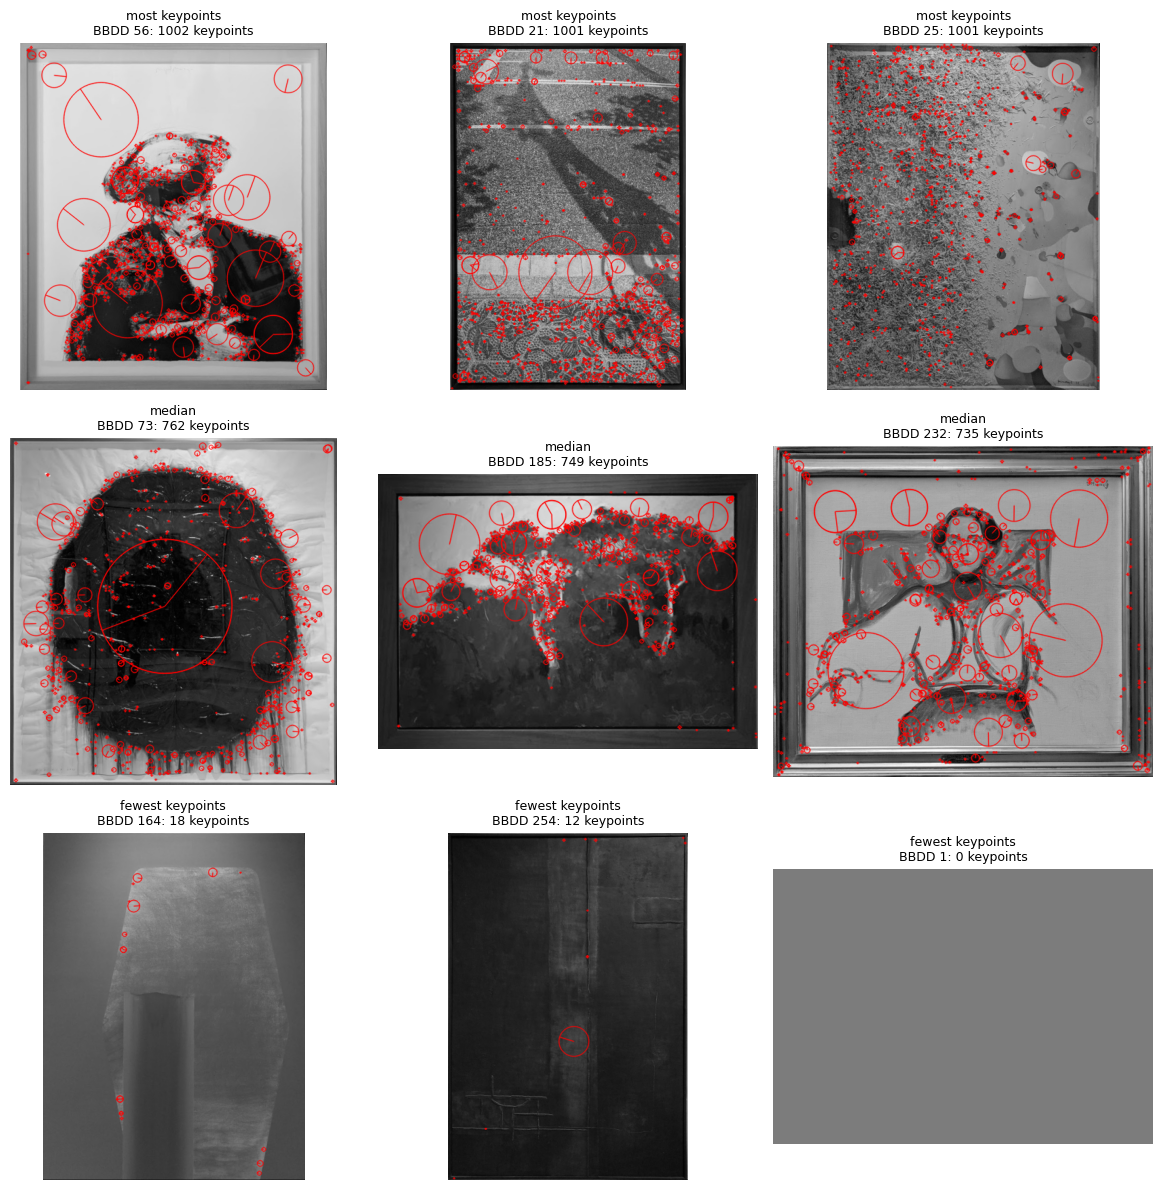

In [116]:
#visual check: keypoints of BBDD images (circle = scale, line = orientation)
#rows: the 3 with most keypoints, the 3 around the median, the 3 with fewest
order = np.argsort(-bbdd_sift_nkp, kind="stable")
mid = len(order) // 2
groups = {"most keypoints": order[:3],
          "median": order[mid - 1:mid + 2],
          "fewest keypoints": order[-3:]}

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, (name, idx) in enumerate(groups.items()):
    for col, i in enumerate(idx):
        ax = axes[row, col]
        kp, _ = bbdd_sift[i]
        vis = cv2.drawKeypoints(to_gray(bbdd_imgs[i]), kp, None, color=(255, 0, 0),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        ax.imshow(vis)
        ax.set_title(f"{name}\nBBDD {bbdd_ids[i]}: {len(kp)} keypoints", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "sift_keypoints_bbdd.png"), dpi=90, bbox_inches="tight")
plt.show()

#### Tentative matches and verification

1. Tentative matches: for every descriptor of the crop we look for its 2 nearest descriptors (distance between two SIFT descriptors calculated with Euclidean (L2) distance) in one BBDD image and keep the match only if `d1 < ratio * d2` (Lowe's ratio test)
2. Verification: RANSAC computes the homography, counts the inliers and keeps the homography with the most inliers
3. Score of a BBDD image: number of RANSAC inliers + (tentative matches / crop descriptors). The second term is always < 1, it only breaks the ties between images with the same number of inliers

In [117]:
RANSAC_THRESHOLD = 5.0 #px, max distance between a point mapped by the homography and its partner
MIN_RANSAC_MATCHES = 4 #a homography needs at least 4 point pairs
bf_l2 = cv2.BFMatcher(cv2.NORM_L2) #brute force, Euclidean distance

def knn_pairs(des_q, des_b):
    #for every query descriptor: return index of the query descriptor, index of its nearest BBDD descriptor, d1 / d2
    if des_q is None or des_b is None or len(des_q) == 0 or len(des_b) < 2:
        return np.empty(0, np.int32), np.empty(0, np.int32), np.empty(0, np.float32)
    pairs = [p for p in bf_l2.knnMatch(des_q, des_b, k=2) if len(p) == 2]
    q = np.array([m.queryIdx for m, _ in pairs], np.int32)
    t = np.array([m.trainIdx for m, _ in pairs], np.int32)
    r = np.array([m.distance / (n.distance + EPS) for m, n in pairs], np.float32)
    return q, t, r

def ransac_inliers(pts_q, pts_b):
    #boolean mask of the matches that agree with the best homography (all False if it cannot be computed)
    if len(pts_q) < MIN_RANSAC_MATCHES:
        return np.zeros(len(pts_q), bool)
    H, mask = cv2.findHomography(pts_q, pts_b, cv2.RANSAC, RANSAC_THRESHOLD)
    return mask.ravel().astype(bool) if H is not None else np.zeros(len(pts_q), bool)

def pair_score(pairs, pts_q, pts_b, ratio, verify):
    #score of one BBDD image for one query image
    q, t, r = pairs
    good = r < ratio
    n = int(good.sum())
    if not verify:
        return n
    inl = ransac_inliers(pts_q[q[good]], pts_b[t[good]]).sum()
    return inl + n / (len(pts_q) + 1)

def make_sift_score_fn(ratio, verify):
    #score_fn for predict_paintings on new photos
    def score_fn(crop):
        kp, des = sift_features(crop)
        pts_q = np.float32([k.pt for k in kp]).reshape(-1, 2)
        return np.array([pair_score(knn_pairs(des, d), pts_q, p, ratio, verify)
                         for d, p in zip(bbdd_sift_des, bbdd_sift_pts)])
    return score_fn

def scores_to_preds(scores, min_score=None, k=K):
    #precomputed scores (for every image, one array per painting)
    return [[rank_to_output(s, min_score, k) for s in ss] for ss in scores]

#knn matching of every QSD1-W4 crop against the whole BBDD (done once)
qsd1_sift, qsd1_sift_pairs = [], []
t_extract = t_match = 0.0
for cc in qsd1_crops:
    feats, pairs = [], []
    for c in cc:
        t0 = time.perf_counter()
        kp, des = sift_features(c)
        t1 = time.perf_counter()
        pairs.append([knn_pairs(des, d) for d in bbdd_sift_des])
        t_extract += t1 - t0
        t_match += time.perf_counter() - t1
        feats.append((kp, np.float32([k.pt for k in kp]).reshape(-1, 2)))
    qsd1_sift.append(feats)
    qsd1_sift_pairs.append(pairs)
n_crops = sum(len(cc) for cc in qsd1_crops)
sift_time_crop, sift_time_match = t_extract / n_crops, t_match / n_crops
qsd1_sift_nkp = np.array([len(kp) for photo in qsd1_sift for kp, _ in photo])
print(f"{n_crops} crops: extraction {1000 * sift_time_crop:.1f} ms per crop, "
      f"knn matching against the {len(bbdd_imgs)} BBDD images {sift_time_match:.2f} s per crop")
print(f"keypoints per crop: mean {qsd1_sift_nkp.mean():.0f}, min {qsd1_sift_nkp.min()}, max {qsd1_sift_nkp.max()}")

def sift_scores(ratio, verify):
    #score of every BBDD image for every QSD1-W4 crop, from the stored knn pairs
    return [[np.array([pair_score(pr, pts_q, pts_b, ratio, verify) for pr, pts_b in zip(prs, bbdd_sift_pts)])
             for prs, (_, pts_q) in zip(photo_pairs, photo_feats)]
            for photo_pairs, photo_feats in zip(qsd1_sift_pairs, qsd1_sift)]

37 crops: extraction 41.2 ms per crop, knn matching against the 287 BBDD images 0.37 s per crop
keypoints per crop: mean 549, min 30, max 1001


#### Choice of the configuration

Grid search on QSD1-W4: ratio from 0.5 to 0.85, with and without RANSAC.

- Low ratio: strict test, few matches but mostly correct. High ratio: more matches, but more wrong ones.
- Metric: map@k on the paintings that are in the museum only. We also compare the score of the right image with the best score of the unknown paintings: the bigger the gap, the easier the unknown detection.
- `MAX_SIDE`, `SIFT_NFEATURES` and `RANSAC_THRESHOLD` stay fixed: changing them means recomputing everything, and with only 30 photos we would risk overfitting QSD1-W4.
- `SIFT_NFEATURES = 2000` was also tested: same best map@1 / map@5 as with 1000, but much slower, so we keep 1000.

In [118]:
def known_mapk(actual, predicted, k=K):
    #map@k only on the paintings that are in the museum
    aps = [apk([a], p_img[j], k) if j < len(p_img) else 0.0
           for a_img, p_img in zip(actual, predicted) for j, a in enumerate(a_img) if a != UNKNOWN]
    return np.mean(aps)

def score_stats(scores, actual):
    #mean score of the right BBDD image (known paintings) and mean best score (unknown paintings)
    right, unk = [], []
    for a_img, s_img in zip(actual, scores):
        for j, a in enumerate(a_img):
            if j >= len(s_img):
                continue
            if a == UNKNOWN:
                unk.append(s_img[j].max())
            else:
                right.append(s_img[j][bbdd_index[a]])
    return np.mean(right), (np.mean(unk) if unk else np.nan)

rows, all_scores = [], {}
for verify in [False, True]:
    for r in [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85]:
        t0 = time.perf_counter()
        sc = sift_scores(r, verify)
        t_score = (time.perf_counter() - t0) / n_crops
        all_scores[(r, verify)] = sc
        pr = scores_to_preds(sc)
        right, unk = score_stats(sc, qsd1_gt)
        rows.append({"ratio": r, "verification": "RANSAC" if verify else "no", "map@1": known_mapk(qsd1_gt, pr, 1),
                     "map@5": known_mapk(qsd1_gt, pr, 5), "map@10": known_mapk(qsd1_gt, pr, 10),
                     "score right image": right, "best score unknown": unk, "s scoring / crop": t_score})
df_ratio = pd.DataFrame(rows)
df_ratio["gap"] = df_ratio["score right image"] / (df_ratio["best score unknown"].fillna(0) + 1)
df_ratio.to_csv(os.path.join(results_dir, "sift_configurations.csv"), index=False)
display(df_ratio.round(3))

#best configuration: highest map@1, then map@5, then the largest relative gap between the right image and the unknown paintings
best = df_ratio.sort_values(["map@1", "map@5", "gap"], ascending=False).iloc[0]
SIFT_RATIO, SIFT_VERIFY = float(best["ratio"]), best["verification"] == "RANSAC"
sift_time_score = float(best["s scoring / crop"])
sift_qsd1_scores = all_scores[(SIFT_RATIO, SIFT_VERIFY)]
sift_preds = scores_to_preds(sift_qsd1_scores) #no unknown detection yet (min_score=None)
sift_score_fn = make_sift_score_fn(SIFT_RATIO, SIFT_VERIFY) #for new photos
print(f"selected: ratio {SIFT_RATIO}, verification {'RANSAC' if SIFT_VERIFY else 'no'}")

,ratio,verification,map@1,map@5,map@10,score right image,best score unknown,s scoring / crop,gap
0,0.50,no,0.724,0.759,0.767,172.962,7.200,0.001,21.093
1,0.55,no,0.724,0.761,0.761,187.885,8.700,0.001,19.370
2,0.60,no,0.724,0.761,0.765,199.115,10.900,0.001,16.732
3,0.65,no,0.724,0.753,0.753,210.731,14.800,0.001,13.337
4,0.70,no,0.724,0.750,0.750,221.846,22.500,0.001,9.440
5,0.75,no,0.724,0.748,0.752,235.154,30.700,0.001,7.418
6,0.80,no,0.724,0.741,0.741,253.500,48.000,0.001,5.173
7,0.85,no,0.690,0.724,0.724,280.462,74.200,0.001,3.730
8,0.50,RANSAC,0.759,0.776,0.781,171.628,0.441,0.008,119.123
9,0.55,RANSAC,0.793,0.810,0.810,185.384,0.842,0.017,100.620


selected: ratio 0.55, verification RANSAC


- Best configuration: ratio 0.55 + RANSAC. map@1 = 0.793 (23/29 known paintings right at top-1), map@5 = 0.810. Ratio 0.60 gives the same map@k but 0.55 wins because of the larger gap (101 vs 51).
- Effect of RANSAC: map@1 0.724 → 0.793, and the unknown paintings get almost no inliers, while the right image gets ~185 on average.

#### Results painting by painting

In [119]:
#one row per painting of QSD1-W4, with the unknown threshold applied (calculated below)
rows = []
for i, (a_img, s_img) in enumerate(zip(qsd1_gt, sift_qsd1_scores)):
    for j, a in enumerate(a_img):
        row = {"file": qsd1_files[i], "painting": j + 1, "correct": a,
               "type": qsd1_type[i] if qsd1_type is not None else ""}
        if j >= len(s_img):
            row["result"] = "no crop" #the painting detection did not find this painting
            rows.append(row)
            continue
        s = s_img[j]
        order = np.argsort(-s, kind="stable")
        said_unknown = s.max() < 5
        row.update({"crop keypoints": len(qsd1_sift[i][j][0]), "1st": int(bbdd_ids[order[0]]),
                    "answer": UNKNOWN if said_unknown else int(bbdd_ids[order[0]]),
                    "1st score": int(s[order[0]]), "2nd score": int(s[order[1]])})
        if a == UNKNOWN:
            row["result"] = "right" if said_unknown else "wrong"
        else:
            row.update({"correct score": int(s[bbdd_index[a]]),
                        "correct rank": int(np.where(bbdd_ids[order] == a)[0][0]) + 1})
            if said_unknown:
                row["result"] = "wrong" #known painting that gets [-1]
            else:
                row["result"] = "right" if row["1st"] == a else "wrong"
        rows.append(row)
df_sift = pd.DataFrame(rows)
df_sift.to_csv(os.path.join(results_dir, "sift_per_painting.csv"), index=False)

known = df_sift[df_sift["correct"] != UNKNOWN]
wrong = known[known["result"] != "right"]

RESULT_TEXT = {"right": "right", "wrong": "wrong", "no crop": "not detected"}
RESULT_COLOUR = {"right": "rgba(0, 170, 0, 0.25)", "wrong": "rgba(220, 0, 0, 0.30)",
                 "no crop": "rgba(255, 150, 0, 0.30)"}

view = pd.DataFrame({
    "photo": df_sift["file"].str.replace(".jpg", "", regex=False),
    "painting": [f"{p} of {n}" + ("" if n == 1 else " (left/top)" if p == 1 else " (right/bottom)" if p == 2 else "")
                 for p, n in zip(df_sift["painting"], df_sift.groupby("file")["painting"].transform("max"))],
    "type": df_sift["type"],
    "result": df_sift["result"].map(RESULT_TEXT),
    "correct id": df_sift["correct"],
    "our answer": df_sift["answer"],
    "best BBDD id": df_sift["1st"],
    "inliers correct": df_sift["correct score"],
    "inliers 1st": df_sift["1st score"],
    "inliers 2nd": df_sift["2nd score"],
    "position of correct": df_sift["correct rank"],
    "query keypoints": df_sift["crop keypoints"],
})

def colour_row(row):
    c = RESULT_COLOUR[df_sift.loc[row.name, "result"]]
    return [f"background-color: {c}"] * len(row)

sty = view.style.apply(colour_row, axis=1).format(precision=0, na_rep="")
try:
    sty = sty.hide(axis="index")
except AttributeError:
    sty = sty.hide_index()
print(f"{len(df_sift)} paintings: {len(known)} from the museum BBDD, {len(df_sift) - len(known)} not in the museum")
print("results:", df_sift["result"].map(RESULT_TEXT).value_counts().to_dict())
display(sty)

39 paintings: 29 from the museum BBDD, 10 not in the museum
results: {'right': 33, 'wrong': 3, 'not detected': 3}


photo,painting,type,result,correct id,our answer,best BBDD id,inliers correct,inliers 1st,inliers 2nd,position of correct,query keypoints
00000,1 of 1,none,right,-1,-1,92,,0,0,,30
00001,1 of 1,color,right,150,150,150,84,84,4,1,1000
00002,1 of 2 (left/top),color,right,48,48,48,259,259,0,1,647
00002,2 of 2 (right/bottom),color,right,251,251,251,40,40,4,1,237
00003,1 of 1,noise,right,32,32,32,50,50,5,1,437
00004,1 of 1,color,right,161,161,161,549,549,4,1,1000
00005,1 of 1,none,right,81,81,81,565,565,0,1,1000
00006,1 of 2 (left/top),none,right,62,62,62,181,181,0,1,705
00006,2 of 2 (right/bottom),none,right,38,38,38,21,21,4,1,186
00007,1 of 1,color,right,-1,-1,209,,0,0,,41


- 33/39 right: 23 known paintings at top-1 and the 10 unknown paintings with [-1]
- Errors (6 known paintings):
  - 5 come from the painting detection, no descriptor can fix them:
    - 00016: 280 not detected (white drawing on a white wall).
    - 00028: only 13 is found, and it is compared with the correct #1 (47), so both are lost.
    - 00020: both paintings in the same crop. SIFT finds both: 117 (the bigger one, 162 inliers) first and 272 second
      (52 inliers), which is why map@5 > map@1. With a crop of the top painting only, SIFT would return 272.
  - 1 comes from SIFT: 00008, the correct image (128) gets 0 inliers. With the threshold it gets [-1].
- Best possible map@1 on the known paintings with this painting detection: 24/29 = 0.828. SIFT gets 23 of these 24.

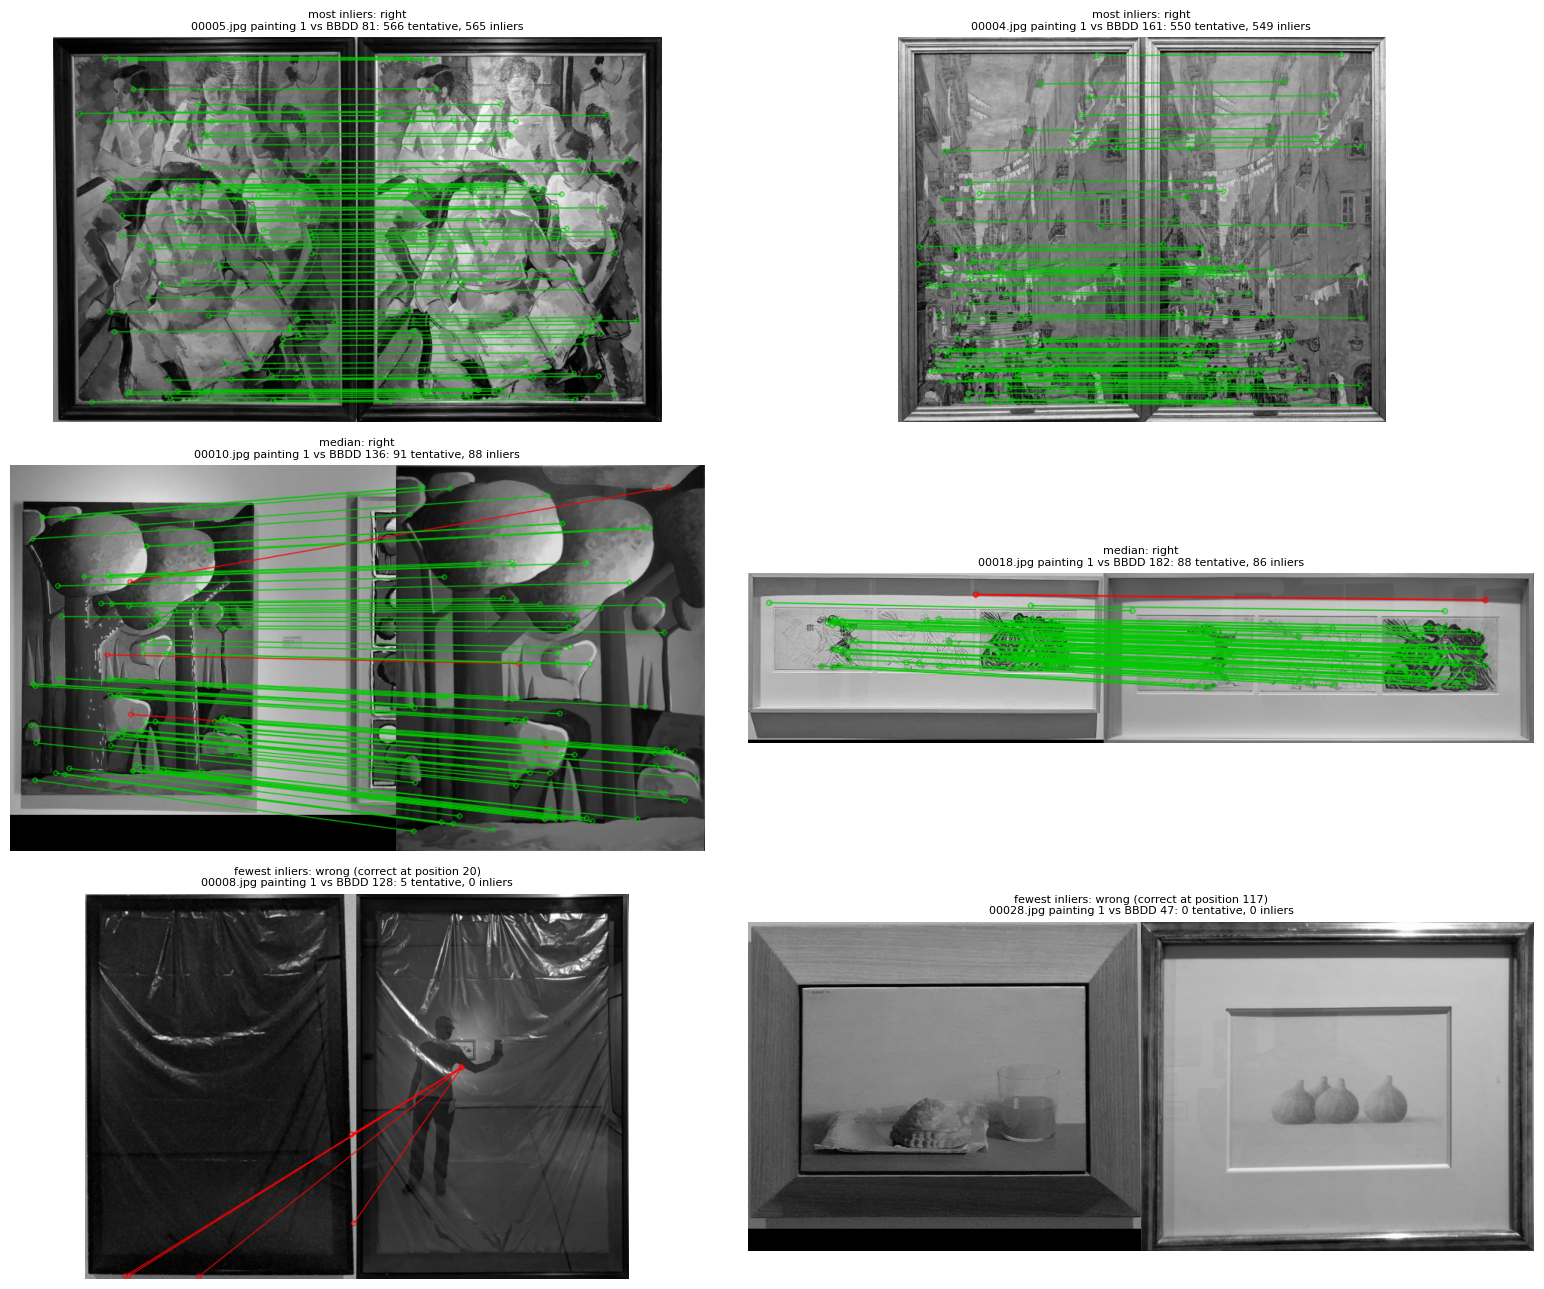

In [120]:
#tentative matches (red) and RANSAC inliers (green) of a painting with its corret BBDD image
#rows: the 2 known paintings with most inliers with the correct image, the 2 around the median, the 2 with fewest
def show_matches(i, j, b, ax, max_lines=80, title=""):
    kp_q, pts_q = qsd1_sift[i][j]
    kp_b, _ = bbdd_sift[bbdd_index[b]]
    q, t, r = qsd1_sift_pairs[i][j][bbdd_index[b]]
    good = r < SIFT_RATIO #tentative matches (ratio test)
    q, t = q[good], t[good]
    inl = ransac_inliers(pts_q[q], bbdd_sift_pts[bbdd_index[b]][t]) #which of them RANSAC keeps
    show = np.random.default_rng(0).permutation(len(q))[:max_lines] #draw at most max_lines, chosen at random
    crop_g, bbdd_g = to_gray(qsd1_crops[i][j]), to_gray(bbdd_imgs[bbdd_index[b]])
    vis = cv2.drawMatches(crop_g, kp_q, bbdd_g, kp_b,
                          [cv2.DMatch(int(q[m]), int(t[m]), 0) for m in show if not inl[m]], None,
                          matchColor=(255, 0, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    vis = cv2.drawMatches(crop_g, kp_q, bbdd_g, kp_b,
                          [cv2.DMatch(int(q[m]), int(t[m]), 0) for m in show if inl[m]], vis,
                          matchColor=(0, 200, 0), flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG | cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax.imshow(vis)
    ax.set_title(f"{title}\n{qsd1_files[i]} painting {j + 1} vs BBDD {b}: {len(q)} tentative, {inl.sum()} inliers", fontsize=8)
    ax.axis("off")

cand = known.dropna(subset=["1st"]).sort_values("correct score", ascending=False, kind="stable")
N = 2 
mid = len(cand) // 2
start = max(mid - N // 2, 0) #first of the N paintings around the median
groups = {"most inliers": cand.iloc[:N], "median": cand.iloc[start:start + N], "fewest inliers": cand.iloc[-N:]}

fig, axes = plt.subplots(3, N, figsize=(8 * N, 13), squeeze=False)
for row, (name, g) in enumerate(groups.items()):
    for col in range(N):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(g):
            r = g.iloc[col]
            status = "right" if r["result"] == "right" else f"wrong (correct at position {int(r['correct rank'])})"
            show_matches(qsd1_files.index(r["file"]), int(r["painting"]) - 1, int(r["correct"]), ax,
                         title=f"{name}: {status}")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "sift_matches.png"), dpi=90, bbox_inches="tight")
plt.show()

#### Scores of known vs unknown paintings

If the best score of the unknown paintings is clearly lower than the score of the known ones, a threshold separates them. The scores of the selected configuration are saved in `results/sift_qsd1_scores.pkl` so that the threshold can be tuned without matching again.

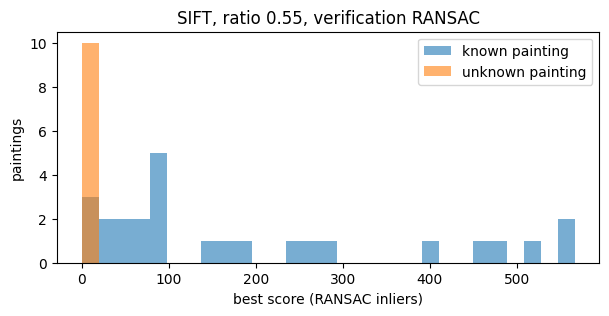

known: min 4.02, median 92.78 | unknown: max 4.02, median 0.05


In [121]:
best_known = [s_img[j].max() for a_img, s_img in zip(qsd1_gt, sift_qsd1_scores) for j, a in enumerate(a_img) if j < len(s_img) and a != UNKNOWN]
best_unknown = [s_img[j].max() for a_img, s_img in zip(qsd1_gt, sift_qsd1_scores) for j, a in enumerate(a_img) if j < len(s_img) and a == UNKNOWN]
bins = np.linspace(0, max(best_known + best_unknown) + 1, 30)
plt.figure(figsize=(7, 3))
plt.hist(best_known, bins=bins, alpha=0.6, label="known painting")
plt.hist(best_unknown, bins=bins, alpha=0.6, label="unknown painting")
plt.xlabel("best score (RANSAC inliers)" if SIFT_VERIFY else "best score (tentative matches)")
plt.ylabel("paintings")
plt.legend()
plt.title(f"SIFT, ratio {SIFT_RATIO}, verification {'RANSAC' if SIFT_VERIFY else 'no'}")
plt.savefig(os.path.join(results_dir, "sift_scores_known_unknown.png"), dpi=90, bbox_inches="tight")
plt.show()
print(f"known: min {min(best_known):.2f}, median {np.median(best_known):.2f} | "
      f"unknown: max {max(best_unknown):.2f}, median {np.median(best_unknown):.2f}" if best_unknown else "")

In [122]:
#known paintings with the lowest best score
low = sorted((s, f, p) for (s, f, p) in
             [(s_img[j].max(), qsd1_files[i], j + 1) for i, (a_img, s_img) in enumerate(zip(qsd1_gt, sift_qsd1_scores))
              for j, a in enumerate(a_img) if j < len(s_img) and a != UNKNOWN])[:5]
for s, f, p in low:
    print(f"{f} painting {p}: best score {s:.2f}")

00008.jpg painting 1: best score 4.02
00016.jpg painting 1: best score 5.14
00025.jpg painting 1: best score 19.05
00006.jpg painting 2: best score 21.14
00013.jpg painting 1: best score 37.31


All unknown paintings get a best score below 5 (at most 4 inliers) and the only known painting below 5 is 00008, which is already wrong, so a threshold of 5 gives [-1] to all unknown paintings without losing any right answer.

In [123]:
#suggested threshold for SIFT: a painting is unknown if its best score is below 5
SIFT_MIN_SCORE = 5
sift_preds_unk = scores_to_preds(sift_qsd1_scores, min_score=SIFT_MIN_SCORE) #[-1] when the best score < 5

#evaluation on all 39 paintings
p, r, f1 = unknown_f1(qsd1_gt, sift_preds_unk)
print(f"min_score = {SIFT_MIN_SCORE}: map@1 {painting_mapk(qsd1_gt, sift_preds_unk, 1):.3f}, "
      f"map@5 {painting_mapk(qsd1_gt, sift_preds_unk, 5):.3f}, map@10 {painting_mapk(qsd1_gt, sift_preds_unk, 10):.3f}")
print(f"unknown detection: precision {p:.2f}, recall {r:.2f}, F1 {f1:.2f}")

min_score = 5: map@1 0.846, map@5 0.859, map@10 0.859
unknown detection: precision 0.83, recall 1.00, F1 0.91


### ORB

FAST keypoints + BRIEF binary descriptor. Matching with Hamming distance + bidirectional matching (`crossCheck`).

### Third descriptor

### Comparison of the descriptors

Speed, number of keypoints, retrieval on QSD1-W4 and robustness to noise and colour changes.

Every descriptor adds one entry to `QSD1_RESULTS`, with the same keys as SIFT: predictions on QSD1-W4 without unknown detection (`min_score=None`), keypoints per image and times. Robustness to noise and colour changes = map@1 of each photo type of QSD1-W4 (`none`, `noise`, `color`, from `augmentations.pkl`).

In [127]:
QSD1_RESULTS = {
    "SIFT": dict(preds=sift_preds, kp_bbdd=bbdd_sift_nkp.mean(), kp_crop=qsd1_sift_nkp.mean(),
                 ms_bbdd=1000 * sift_time_bbdd, ms_crop=1000 * sift_time_crop,
                 s_match_crop=sift_time_match + sift_time_score), 
}

def type_mapk(actual, predicted, t, k=1):
    keep = [i for i in range(len(actual)) if qsd1_type[i] == t]
    return known_mapk([actual[i] for i in keep], [predicted[i] for i in keep], k) if keep else np.nan

#paintings that no descriptor can get right because of the painting detection 
DETECTION_ERRORS = {("00016.jpg", 2),                    #280 not detected
                    ("00020.jpg", 1), ("00020.jpg", 2),  #272 and 117 in the same crop
                    ("00028.jpg", 1), ("00028.jpg", 2)}  #only 13 found, compared with 47

def good_crop_mapk(actual, predicted, t=None, k=1):
    #map@k only on the known paintings with a correct crop
    aps = []
    for i, (a_img, p_img) in enumerate(zip(actual, predicted)):
        if t is not None and qsd1_type[i] != t:
            continue
        for j, a in enumerate(a_img):
            if a == UNKNOWN or (qsd1_files[i], j + 1) in DETECTION_ERRORS:
                continue
            aps.append(apk([a], p_img[j], k))
    return np.mean(aps) if aps else np.nan

rows = []
for name, r in QSD1_RESULTS.items():
    row = {"method": name, "keypoints BBDD": r["kp_bbdd"], "keypoints crop": r["kp_crop"],
           "ms / BBDD image": r["ms_bbdd"], "ms / crop": r["ms_crop"], "s matching / crop": r["s_match_crop"],
           "map@1": known_mapk(qsd1_gt, r["preds"], 1), "map@5": known_mapk(qsd1_gt, r["preds"], 5)}
    if qsd1_type is not None:
        for t in ["none", "noise", "color"]:
            row[f"map@1 {t}"] = type_mapk(qsd1_gt, r["preds"], t)
    row["map@1 good crop"] = good_crop_mapk(qsd1_gt, r["preds"])
    if qsd1_type is not None:
        for t in ["none", "noise", "color"]:
            row[f"map@1 {t} good crop"] = good_crop_mapk(qsd1_gt, r["preds"], t)
    rows.append(row)
df_comp = pd.DataFrame(rows).set_index("method")
df_comp.to_csv(os.path.join(results_dir, "descriptors_comparison.csv"))
display(df_comp.round(3))
if qsd1_type is not None:
    print("known paintings per photo type:", {t: sum(a != UNKNOWN for i in np.where(qsd1_type == t)[0] for a in qsd1_gt[i])
                                              for t in ["none", "noise", "color"]})

,keypoints BBDD,keypoints crop,ms / BBDD image,ms / crop,s matching / crop,map@1,map@5,map@1 none,map@1 noise,map@1 color,map@1 good crop,map@1 none good crop,map@1 noise good crop,map@1 color good crop
method,,,,,,,,,,,,,,
SIFT,655.927,549.432,53.546,41.235,0.388,0.793,0.81,0.875,0.857,0.714,0.958,1.0,0.857,1.0


known paintings per photo type: {'none': 8, 'noise': 7, 'color': 14}


### Similarity metrics

L2 vs Hamming, ratio test vs cross-check.

### Unknown detection

Threshold on the number of matches (`min_score`), chosen by optimizing the F1 of the unknown detection on QSD1-W4.

## TASK 3: Evaluation on QSD1-W4 and comparison with the best Week 3 system

Best Week 3 system: denoising + painting detection + LBP 8x8 with radii 1, 2, 3 (P=8), L1 distance.

## TASK 4: Blind submission (QST1-W4)

Only the best method (`method1`), with `[-1]` for unknown paintings. Nothing is tuned on the test set.